# Détection d'intrusions réseau par GNN — NF-UNSW-NB15-v3

Notebook qui enchaîne tout le pipeline : exploration, préparation, graphes, baselines, E-GraphSAGE, évaluation.

## 0. Imports et configuration

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [2]:
SEED = 42
SAMPLE_FRAC = 1.0  # < 1.0 pour développer sur un sous-échantillon

# Le notebook peut être lancé depuis la racine du dépôt ou depuis notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "NF-UNSW-NB15-v3.csv"

random.seed(SEED)
np.random.seed(SEED)

print(f"pandas {pd.__version__} | numpy {np.__version__}")
print(f"Données : {DATA_PATH} (existe : {DATA_PATH.exists()})")

pandas 3.0.3 | numpy 2.4.5
Données : C:\Users\Busin\AI-INTRUSIONS-DETECTION\data\NF-UNSW-NB15-v3.csv (existe : True)


In [3]:
# Style commun à toutes les figures : bénin = bleu, attaque = orange
BENIGN, ATTACK = "#2a78d6", "#eb6834"
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "font.size": 9, "text.color": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. Chargement et affichage du dataset

In [4]:
df = pd.read_csv(DATA_PATH)
if SAMPLE_FRAC < 1.0:
    df = df.sample(frac=SAMPLE_FRAC, random_state=SEED).reset_index(drop=True)

print(f"Shape : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Mémoire : {df.memory_usage(deep=True).sum() / 1e6:.1f} Mo")

Shape : 2,365,424 lignes x 55 colonnes


Mémoire : 1457.8 Mo


In [5]:
df.head()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1424242193040,1424242193043,59.166.0.2,4894,149.171.126.3,53,17,5.0,146,2,178,2,0,0,0,2,0,0,31,31,89,73,73,89,89.000000,73.000000,0,0,0,0,389333,474666,4,0,0,0,0,0,0,0,0,46779,1,60,0,0,0,0,0,0,0,0,0,0,Benign
1,1424242192744,1424242193079,59.166.0.4,52671,149.171.126.6,31992,6,11.0,4704,28,2976,28,27,27,27,335,334,334,31,32,984,52,52,984,8.883582,14.041791,1988,7,1068,6,112000,70857,34,18,2,2,0,14480,14480,50176,196,0,0,0,0,0,91,12,19,0,90,12,19,0,Benign
2,1424242190649,1424242193109,59.166.0.0,47290,149.171.126.9,6881,6,37.0,13662,238,548216,438,27,27,27,2460,2459,2459,31,32,1500,52,52,1500,222.852033,5.553659,1735,21,272908,196,44411,1782091,288,0,4,32,352,65160,34752,50944,199,0,0,0,0,0,1843,10,119,0,1843,5,88,0,Benign
3,1424242193145,1424242193146,59.166.0.8,43310,149.171.126.7,53,17,5.0,146,2,178,2,0,0,0,1,0,0,31,31,89,73,73,89,178.000000,146.000000,0,0,0,0,584000,712000,4,0,0,0,0,0,0,0,0,3211,1,60,0,0,0,0,0,0,0,0,0,0,Benign
4,1424242193239,1424242193241,59.166.0.1,45870,149.171.126.1,53,17,5.0,130,2,162,2,0,0,0,1,0,0,31,31,81,65,65,81,162.000000,130.000000,0,0,0,0,520000,648000,4,0,0,0,0,0,0,0,0,5771,1,60,0,0,0,0,0,0,0,0,0,0,Benign


In [6]:
print(df.columns.tolist())

['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 

In [7]:
df.dtypes.to_frame("type")

,type
FLOW_START_MILLISECONDS,int64
FLOW_END_MILLISECONDS,int64
IPV4_SRC_ADDR,str
L4_SRC_PORT,int64
IPV4_DST_ADDR,str
L4_DST_PORT,int64
PROTOCOL,int64
L7_PROTO,float64
IN_BYTES,int64
IN_PKTS,int64


## 2. Analyse exploratoire

### 2.1 Valeurs manquantes et infinies

In [8]:
num_cols = df.select_dtypes("number").columns
quality = pd.DataFrame({
    "NaN": df.isna().sum(),
    "inf": np.isinf(df[num_cols]).sum(),
}).fillna(0).astype(int)
quality[quality.sum(axis=1) > 0]

,NaN,inf
DST_TO_SRC_SECOND_BYTES,0,122493
SRC_TO_DST_SECOND_BYTES,63425,59068


In [9]:
# D'où viennent ces valeurs ? Les deux colonnes sont des débits (octets / seconde).
RATE_COLS = ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
invalid = ~np.isfinite(df[RATE_COLS]).all(axis=1)
zero_duration = df["FLOW_DURATION_MILLISECONDS"] == 0

print(f"Flux avec un débit NaN ou infini : {invalid.sum():,}")
print(f"Flux de durée nulle              : {zero_duration.sum():,}")
print(f"Les deux ensembles sont identiques : {(invalid == zero_duration).all()}")
print(f"Part d'attaques parmi ces flux : {df.loc[invalid, 'Label'].mean():.1%} "
      f"(contre {df['Label'].mean():.1%} dans tout le dataset)")

Flux avec un débit NaN ou infini : 122,493
Flux de durée nulle              : 122,493
Les deux ensembles sont identiques : True
Part d'attaques parmi ces flux : 29.2% (contre 5.4% dans tout le dataset)


### 2.2 Doublons

In [10]:
dup = df.duplicated()
print(f"Lignes strictement identiques à une ligne précédente : {dup.sum():,} ({dup.mean():.2%})")
df.loc[dup, "Attack"].value_counts().to_frame("doublons")

Lignes strictement identiques à une ligne précédente : 14,815 (0.63%)


,doublons
Attack,
Benign,14801
DoS,9
Exploits,4
Backdoor,1


### 2.3 Répartition des classes

In [11]:
label_counts = df["Label"].value_counts().rename({0: "Bénin (0)", 1: "Attaque (1)"})
pd.DataFrame({"flux": label_counts, "part (%)": (100 * label_counts / len(df)).round(2)})

,flux,part (%)
Label,,
Bénin (0),2237731,94.6
Attaque (1),127693,5.4


In [12]:
attack_counts = df["Attack"].value_counts()
pd.DataFrame({"flux": attack_counts, "part (%)": (100 * attack_counts / len(df)).round(3)})

,flux,part (%)
Attack,,
Benign,2237731,94.602
Exploits,42748,1.807
Fuzzers,33816,1.430
Generic,19651,0.831
Reconnaissance,17074,0.722
DoS,5980,0.253
Backdoor,4659,0.197
Shellcode,2381,0.101
Analysis,1226,0.052


In [13]:
# Cohérence entre les deux colonnes cibles
pd.crosstab(df["Attack"], df["Label"])

Label,0,1
Attack,,
Analysis,0,1226
Backdoor,0,4659
Benign,2237731,0
DoS,0,5980
Exploits,0,42748
Fuzzers,0,33816
Generic,0,19651
Reconnaissance,0,17074
Shellcode,0,2381


### 2.4 Adresses IP (futurs nœuds du graphe)

In [14]:
src_ips, dst_ips = set(df["IPV4_SRC_ADDR"]), set(df["IPV4_DST_ADDR"])
print(f"IP sources uniques      : {len(src_ips)}")
print(f"IP destinations uniques : {len(dst_ips)}")
print(f"IP uniques au total     : {len(src_ips | dst_ips)}")

attack_src = set(df.loc[df["Label"] == 1, "IPV4_SRC_ADDR"])
benign_src = set(df.loc[df["Label"] == 0, "IPV4_SRC_ADDR"])
print(f"\nIP sources émettant des attaques : {len(attack_src)}")
print(f"  dont émettant aussi du trafic bénin : {len(attack_src & benign_src)}")

IP sources uniques      : 40
IP destinations uniques : 40
IP uniques au total     : 44



IP sources émettant des attaques : 4
  dont émettant aussi du trafic bénin : 0


In [15]:
# Trafic émis par les IP sources d'attaques
(df[df["IPV4_SRC_ADDR"].isin(attack_src)]
 .groupby("IPV4_SRC_ADDR")["Label"]
 .agg(flux="size", attaques="sum", part_attaques="mean")
 .sort_values("attaques", ascending=False))

,flux,attaques,part_attaques
IPV4_SRC_ADDR,,,
175.45.176.1,35176,35176,1.0
175.45.176.3,33820,33820,1.0
175.45.176.0,31442,31442,1.0
175.45.176.2,27255,27255,1.0


### 2.5 Dimension temporelle

In [16]:
start = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms")
end = pd.to_datetime(df["FLOW_END_MILLISECONDS"], unit="ms")
print(f"Premier flux : {start.min()}")
print(f"Dernier flux : {end.max()}")
print(f"Flux dont la fin précède le début : {(end < start).sum()}")

# Types d'attaque par jour de capture
pd.crosstab(df["Attack"], start.dt.date.rename("jour"), margins=True, margins_name="Total")

Premier flux : 2015-01-22 11:49:36.907000
Dernier flux : 2015-02-18 12:29:25.011000
Flux dont la fin précède le début : 0


jour,2015-01-22,2015-01-23,2015-02-18,Total
Attack,,,,
Analysis,267,0,959,1226
Backdoor,43,0,4616,4659
Benign,1078112,39778,1119841,2237731
DoS,624,0,5356,5980
Exploits,5622,0,37126,42748
Fuzzers,6046,0,27770,33816
Generic,2405,0,17246,19651
Reconnaissance,2155,0,14919,17074
Shellcode,280,0,2101,2381


## 3. Nettoyage

- **Infinis → NaN** dans les deux colonnes de débit (division par une durée nulle). L'imputation se fera plus tard, avec la médiane du train uniquement, pour éviter toute fuite de données.
- **Suppression des doublons exacts** (lignes identiques sur les 55 colonnes, horodatage à la milliseconde compris).
- **Types** : `Attack` en catégorie, ajout de `start_time` (date lisible du début de flux).
- `ID_COLS` liste les colonnes qui ne devront jamais servir de features.

In [17]:
n_before = len(df)

df[RATE_COLS] = df[RATE_COLS].replace([np.inf, -np.inf], np.nan)
df = df.drop_duplicates().reset_index(drop=True)
df["Attack"] = df["Attack"].astype("category")
df["start_time"] = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms")

ID_COLS = [
    "IPV4_SRC_ADDR", "IPV4_DST_ADDR",
    "FLOW_START_MILLISECONDS", "FLOW_END_MILLISECONDS", "start_time",
    "Label", "Attack",
]

print(f"Lignes avant : {n_before:,}")
print(f"Lignes après : {len(df):,} ({n_before - len(df):,} doublons supprimés)")

Lignes avant : 2,365,424
Lignes après : 2,350,609 (14,815 doublons supprimés)


In [18]:
# Vérification
num_cols = df.select_dtypes("number").columns
print(f"Valeurs infinies restantes : {np.isinf(df[num_cols]).sum().sum()}")
print(f"Doublons restants          : {df.duplicated().sum()}")
print(f"Attaques : {df['Label'].sum():,} ({df['Label'].mean():.2%})")
print("\nNaN restants (à imputer après le split) :")
print(df.isna().sum()[df.isna().sum() > 0].to_string())

Valeurs infinies restantes : 0


Doublons restants          : 0
Attaques : 127,679 (5.43%)

NaN restants (à imputer après le split) :


SRC_TO_DST_SECOND_BYTES    109125
DST_TO_SRC_SECOND_BYTES    109125


In [19]:
# Statistiques descriptives des features numériques
df.drop(columns=ID_COLS).describe().T

,count,mean,std,min,25%,50%,75%,max
L4_SRC_PORT,2350609.0,3.271109e+04,1.912163e+04,0.000000,16033.000000,32817.000000,49195.0,6.553500e+04
L4_DST_PORT,2350609.0,1.120527e+04,1.842297e+04,0.000000,25.000000,80.000000,14888.0,6.553500e+04
PROTOCOL,2350609.0,8.683827e+00,6.372777e+00,0.000000,6.000000,6.000000,6.0,2.550000e+02
L7_PROTO,2350609.0,2.363672e+01,2.128450e+01,0.000000,5.000000,36.000000,37.0,4.210000e+02
IN_BYTES,2350609.0,4.437993e+03,6.791141e+04,1.000000,481.000000,1580.000000,3078.0,2.702093e+07
IN_PKTS,2350609.0,3.547415e+01,7.858391e+01,1.000000,4.000000,18.000000,44.0,2.016600e+04
OUT_BYTES,2350609.0,3.451089e+04,1.554932e+05,0.000000,312.000000,2456.000000,14740.0,1.465675e+07
OUT_PKTS,2350609.0,4.496146e+01,1.166291e+02,0.000000,4.000000,18.000000,44.0,1.102400e+04
TCP_FLAGS,2350609.0,1.987736e+01,1.108886e+01,0.000000,19.000000,27.000000,27.0,3.100000e+01
CLIENT_TCP_FLAGS,2350609.0,1.959674e+01,1.100648e+01,0.000000,19.000000,25.000000,27.0,3.100000e+01


## 4. Visualisations

### 4.1 Types d'attaque

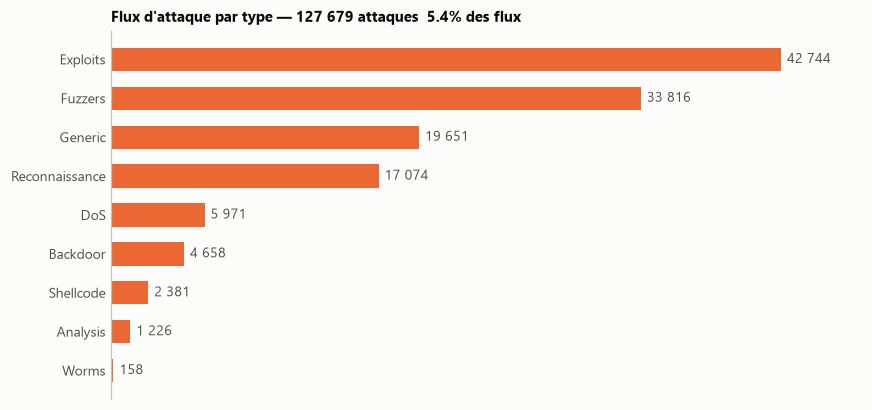

In [20]:
counts = df.loc[df["Label"] == 1, "Attack"].astype(str).value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(counts.index, counts.values, height=0.6, color=ATTACK)
ax.bar_label(bars, labels=[f"{v:,}".replace(",", " ") for v in counts.values], padding=4, color=INK2)
ax.set_title(f"Flux d'attaque par type — {counts.sum():,} attaques, ".replace(",", " ")
             + f"{df['Label'].mean():.1%} des flux")
ax.set_xlim(0, counts.max() * 1.12)
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", bottom=False, labelbottom=False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### 4.2 Trafic dans le temps

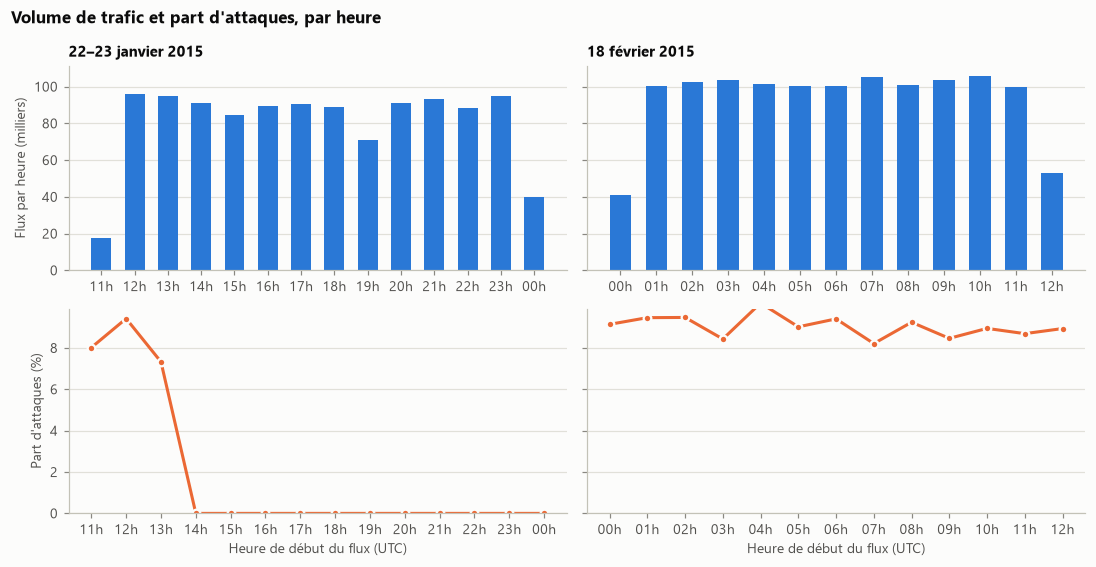

In [21]:
hour = df["start_time"].dt.floor("h")
hourly = df.groupby(hour)["Label"].agg(flux="size", part_attaques="mean")
periods = {
    "22–23 janvier 2015": hourly[hourly.index < "2015-02-01"],
    "18 février 2015": hourly[hourly.index >= "2015-02-01"],
}

fig, axes = plt.subplots(2, 2, figsize=(10, 5.2), sharey="row")
for col, (name, sub) in enumerate(periods.items()):
    x = np.arange(len(sub))
    labels = sub.index.strftime("%Hh")

    top = axes[0, col]
    top.bar(x, sub["flux"] / 1000, width=0.6, color=BENIGN)
    top.set_title(name)
    top.set_xticks(x, labels)

    bottom = axes[1, col]
    bottom.plot(x, 100 * sub["part_attaques"], color=ATTACK, marker="o", markersize=5,
                markeredgecolor=SURFACE, markeredgewidth=1.5)
    bottom.set_xticks(x, labels)
    bottom.set_ylim(bottom=0)
    bottom.set_xlabel("Heure de début du flux (UTC)")

axes[0, 0].set_ylabel("Flux par heure (milliers)")
axes[1, 0].set_ylabel("Part d'attaques (%)")
fig.suptitle("Volume de trafic et part d'attaques, par heure", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.3 Distribution de quelques features, bénin vs attaque

Les features de volume sont très asymétriques : l'axe horizontal est en échelle logarithmique (`log10(1 + x)`). Chaque courbe est normalisée séparément (densité), pour comparer les formes malgré le déséquilibre des classes.

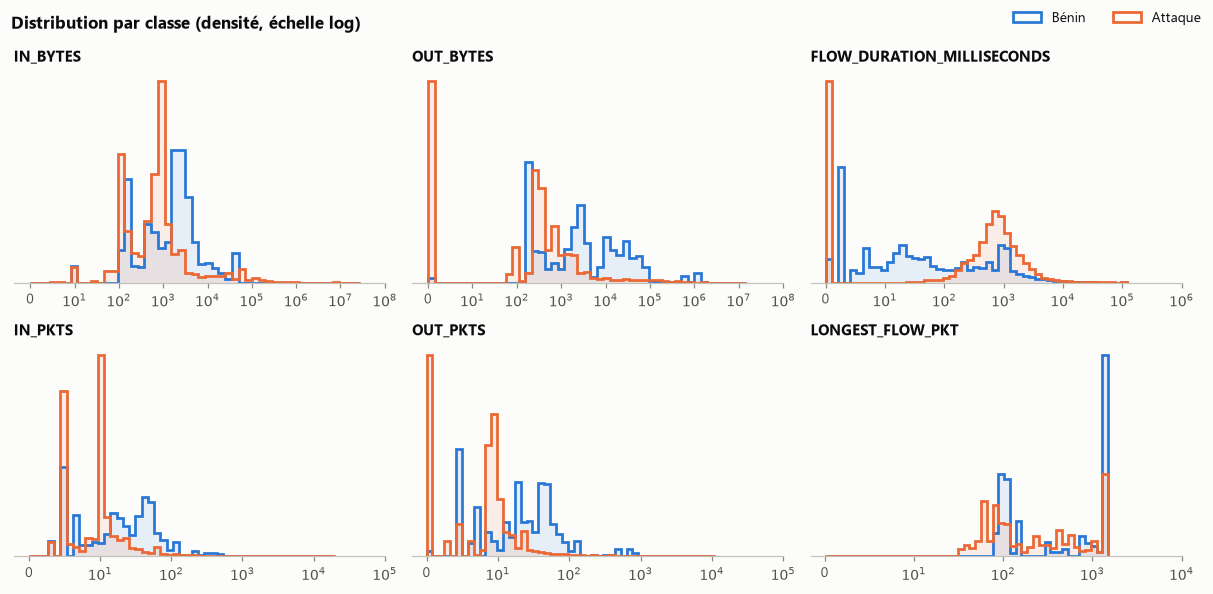

In [22]:
features = [
    "IN_BYTES", "OUT_BYTES", "FLOW_DURATION_MILLISECONDS",
    "IN_PKTS", "OUT_PKTS", "LONGEST_FLOW_PKT",
]
is_attack = df["Label"] == 1

fig, axes = plt.subplots(2, 3, figsize=(11, 5.4))
for ax, feat in zip(axes.flat, features):
    values = np.log10(1 + df[feat])
    bins = np.linspace(0, values.max(), 50)
    for mask, color, label in [(~is_attack, BENIGN, "Bénin"), (is_attack, ATTACK, "Attaque")]:
        ax.hist(values[mask], bins=bins, density=True, histtype="stepfilled", color=color, alpha=0.10)
        ax.hist(values[mask], bins=bins, density=True, histtype="step", color=color,
                linewidth=1.8, label=label)
    ticks = np.arange(0, int(np.ceil(values.max())) + 1)
    ax.set_xticks(ticks, ["0"] + [f"$10^{t}$" for t in ticks[1:]])
    ax.set_title(feat)
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["left"].set_visible(False)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncols=2)
fig.suptitle("Distribution par classe (densité, échelle log)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.4 Corrélations entre features

Corrélation de Spearman (robuste aux distributions asymétriques), calculée sur un échantillon de 200 000 flux.

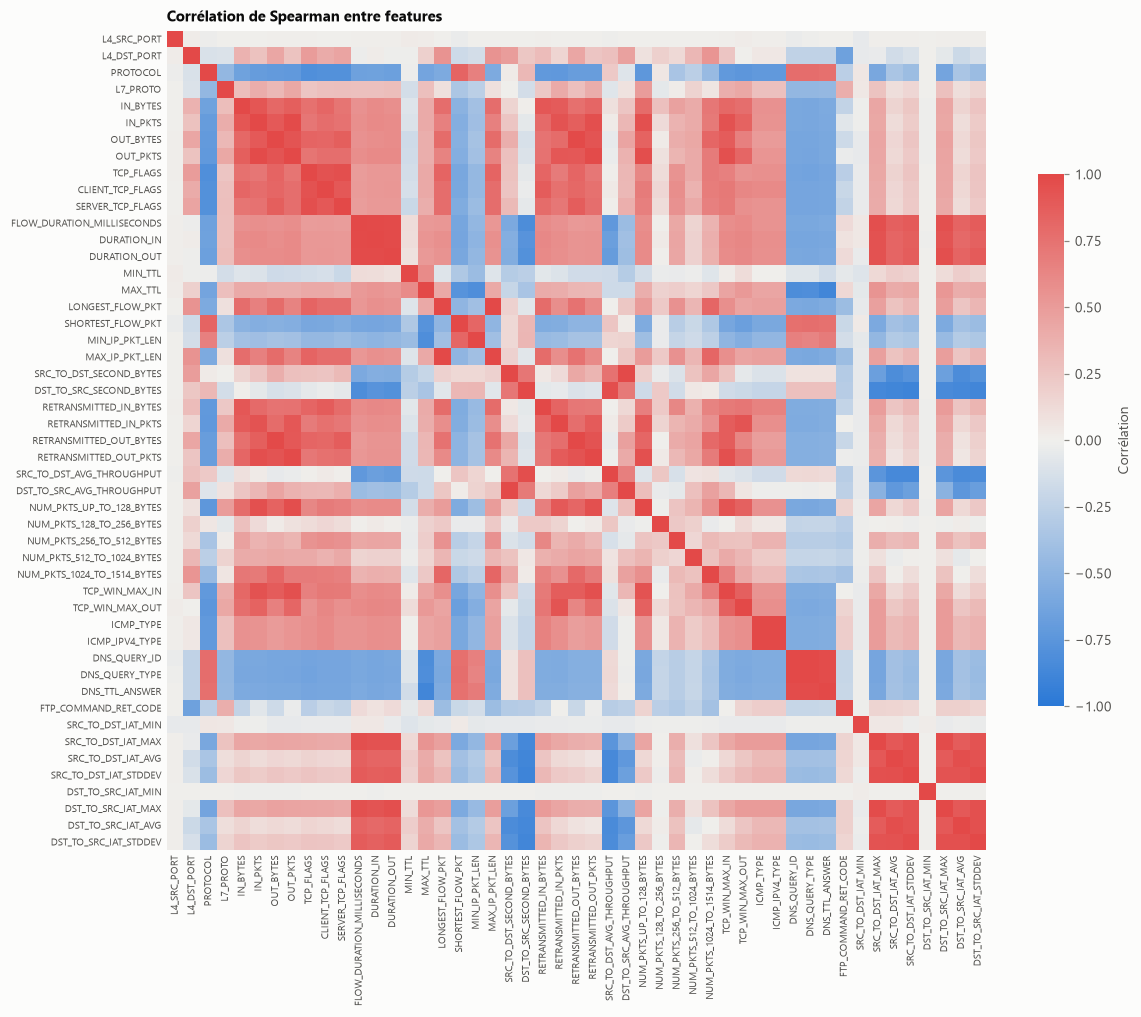

In [23]:
feature_cols = [c for c in df.columns if c not in ID_COLS]
sample = df[feature_cols].sample(n=min(200_000, len(df)), random_state=SEED)
corr = sample.corr(method="spearman")

diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(corr)), corr.index, fontsize=6.5)
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Corrélation de Spearman entre features")
fig.colorbar(im, ax=ax, shrink=0.6, label="Corrélation").outline.set_visible(False)
plt.tight_layout()
plt.show()

In [24]:
# Paires de features quasi redondantes (|corrélation| >= 0.95)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("spearman").rename_axis(["feature_1", "feature_2"]).reset_index()
pairs[pairs["spearman"].abs() >= 0.95].sort_values("spearman", ascending=False).reset_index(drop=True)

,feature_1,feature_2,spearman
0,LONGEST_FLOW_PKT,MAX_IP_PKT_LEN,1.000000
1,ICMP_TYPE,ICMP_IPV4_TYPE,1.000000
2,DNS_QUERY_ID,DNS_QUERY_TYPE,0.993278
3,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_AVG_THROUGHPUT,0.989997
4,FLOW_DURATION_MILLISECONDS,DURATION_IN,0.984962
5,OUT_BYTES,RETRANSMITTED_OUT_BYTES,0.984518
6,FLOW_DURATION_MILLISECONDS,DURATION_OUT,0.982687
7,OUT_PKTS,RETRANSMITTED_OUT_PKTS,0.981350
8,IN_PKTS,OUT_PKTS,0.980489
9,DURATION_IN,DURATION_OUT,0.976592
